# Find SWOT passes in a time interval and region

This example predicts when nominal SWOT ground tracks cross a geographic bounding box. Times are UTC and the region is `[longitude_min, longitude_max, latitude_min, latitude_max]`.

In [1]:
import sys
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import satpass

print(f"SatPass version: {satpass.__version__}")

import pandas as pd

SatPass version: 0.1.0


## Set the time interval and region

In [2]:
start_time = pd.Timestamp("2026-08-01 00:00:00")
end_time = pd.Timestamp("2026-08-10 23:59:59")
region = [140.0, 150.0, -45.0, -35.0]

## Calculate predicted passes

In [3]:
nominal = satpass.NominalTrack('sw')
tracks = nominal.select_in_area(region)

In [4]:
passes = satpass.sat_pass(
    mission="sw",
    date=[start_time, end_time],
    area=region,
)

passes

,track,direction,cycle,lon0_360,time,subcycle_rank,subcycle,subcycle_global
2026-08-01 04:28:00,32,des,54.0,146.553920,2026-08-01 04:28:00,1,3.0,3.0
2026-08-01 15:12:00,45,asc,54.0,142.913827,2026-08-01 15:12:00,3,1.0,1.0
2026-08-02 04:27:00,60,des,54.0,144.095179,2026-08-02 04:27:00,2,3.0,3.0
2026-08-02 15:11:00,73,asc,54.0,140.446365,2026-08-02 15:11:00,4,1.0,1.0
2026-08-03 04:26:00,88,des,54.0,141.628065,2026-08-03 04:26:00,3,3.0,3.0
2026-08-04 04:25:00,116,des,54.0,139.161922,2026-08-04 04:25:00,4,3.0,3.0
2026-08-08 13:23:00,239,asc,54.0,151.548778,2026-08-08 13:23:00,0,0.0,0.0
2026-08-09 14:06:00,267,asc,54.0,149.081536,2026-08-09 14:06:00,1,0.0,0.0
2026-08-10 03:23:00,282,des,54.0,150.254131,2026-08-10 03:23:00,0,2.0,2.0
2026-08-10 14:10:00,295,asc,54.0,146.613870,2026-08-10 14:10:00,2,0.0,0.0


## Plot the tracks crossing the region in the given time interval

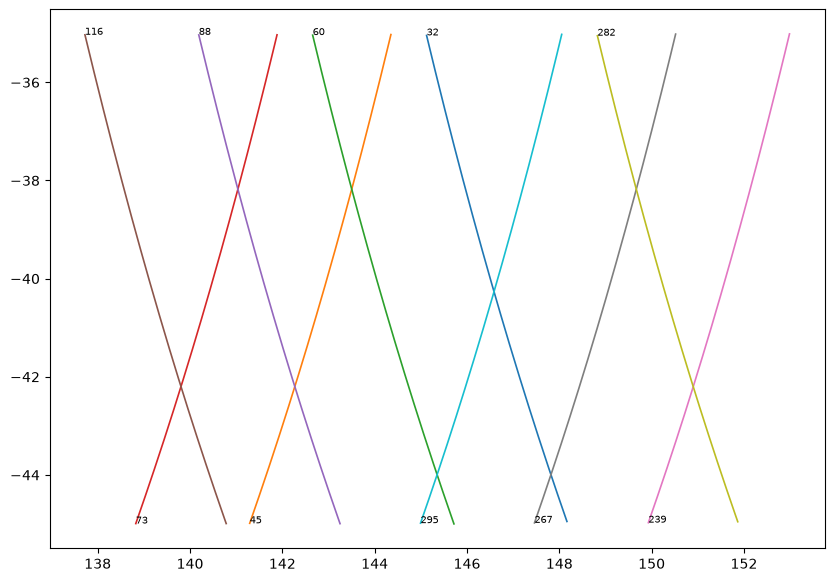

In [5]:
swot = satpass.NominalTrack("sw")
tracks = swot.select_in_area(region, extend_to_latitude_bounds=True)
selected_track_numbers = set(passes["track"]) if not passes.empty else set()
tracks = tracks[tracks["track"].isin(selected_track_numbers)]

fig, ax = plt.subplots(figsize=(10, 7))

for track_number, track in tracks.groupby("track"):
    ax.plot(
        track["lon"],
        track["lat"],
        linewidth=1.2,
    )
    ax.text(track["lon"].iloc[0], track["lat"].iloc[0], str(track_number), fontsize=7)